In [1]:
from pathlib import Path
import subprocess
import sys
from google.colab import drive

DRIVE = Path('/content/drive')
drive.mount('/content/drive', force_remount=True)

ROOT = DRIVE / "MyDrive" / "doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval"

PACKAGE_DIR = ROOT / 'python_packages'
PACKAGE_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PACKAGE_DIR))
print(PACKAGE_DIR.resolve())

import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter, FixedLocator
import numpy as np
import string
import pandas as pd

sys.path.insert(0, str(ROOT / "src"))

DATA_ROOT = ROOT / "data"
PREDS_ROOT = ROOT/ "outputs" / "aa_geoph_fluids"

VAR_DS = "precip"

Mounted at /content/drive
/content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages


/content/drive/MyDrive/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [2]:
models = ["BerGamma", "DDPM", "FlowMatch"]

preds_models = {
    m: xr.open_dataset(list((PREDS_ROOT / m).glob("./*.nc") )[0])
    for m in models
}


ds_y_test = xr.open_dataset(DATA_ROOT / "predictands" / f"pr_SESA_ERA5.nc").sel(
    time=preds_models[models[0]].time.values
)
# ds_y_test


In [3]:
import statistical_downscaling.evaluation.stats.univariate.ralsd as ralsd
CHUNK = dict(time=365)

E_ref = ralsd.isotropic_psd(ds_y_test[VAR_DS].chunk(CHUNK)).compute()
E_mod = {m: ralsd.isotropic_psd(d[VAR_DS].chunk(CHUNK)).compute()
         for m, d in preds_models.items()}

psd_ref = ralsd.psd_mean(E_ref)                                   # (k)
psd_mod = {m: ralsd.psd_mean(E) for m, E in E_mod.items()}        # {modelo: (k)}
ratios  = {m: ralsd.psd_ratio(E, E_ref) for m, E in E_mod.items()}

to_rapsd = lambda p: p / (2 * np.pi * p["k"])
rapsd_ref = to_rapsd(psd_ref)
rapsd_mod = {m: to_rapsd(p) for m, p in psd_mod.items()}

In [4]:
MIN_WL = 50

tabla = pd.DataFrame({
    "RALSD [dB]": {m: ralsd.ralsd(psd_ref, p) for m, p in psd_mod.items()},
    f"RALSD [dB] (≥ {MIN_WL} km)":    {m: ralsd.ralsd(psd_ref, p, min_wavelength=MIN_WL) for m, p in psd_mod.items()},
}).round(2)
tabla

,RALSD [dB],RALSD [dB] (≥ 50 km)
BerGamma,8.76,8.76
DDPM,0.64,0.64
FlowMatch,0.27,0.27


In [5]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]


def _wavelength_axis(ax, lam, ticks, xlim):
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([t for t in ticks if lam.min() <= t <= lam.max()]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(*xlim)
    ax.set_xlabel("Wavelength (km)")


def plot_rapsd(psd_ref, psd_mod: dict, ref_name="Reference", units="",
               title="Radially Averaged Power Spectral Density", ax=None,
               ticks=(1000, 400, 200, 100, 50), xlim=(1800, 50), colors: dict | None = None):
    """psd_ref: DataArray (k); psd_mod: {modelo: DataArray (k)}. Log-log."""
    colors = colors or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)

    for i, (m, p) in enumerate(psd_mod.items()):
        ax.plot(p["wavelength"], p, lw=2, label=m,
                color=colors.get(m, SERIES_COLORS[i % len(SERIES_COLORS)]))
    ax.plot(psd_ref["wavelength"], psd_ref, color="k", lw=2.2, ls="--", label=ref_name, zorder=5)

    ax.set_yscale("log")
    _wavelength_axis(ax, psd_ref["wavelength"], ticks, xlim)
    u = f" [({units})² km]" if units else ""
    ax.set_ylabel(f"RAPSD{u}")
    if title:
        ax.set_title(title, fontweight="bold")
    ax.legend(frameon=True, fontsize=9)
    return ax


def plot_rapsd_ratio(ratios: dict, ref_name="Reference", title="RAPSD ratio", ax=None,
                     ticks=(1000, 400, 200, 100, 50), xlim=(1800, 50),
                     colors: dict | None = None, logy=True):
    """ratios: {modelo: DataArray (k)} de psd_ratio. 1 = igual a la referencia."""
    colors = colors or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)

    for i, (m, r) in enumerate(ratios.items()):
        ax.plot(r["wavelength"], r, lw=2, label=m,
                color=colors.get(m, SERIES_COLORS[i % len(SERIES_COLORS)]))
    ax.axhline(1, color="k", lw=1.5, ls="--", label=ref_name, zorder=5)

    if logy:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    first = next(iter(ratios.values()))
    _wavelength_axis(ax, first["wavelength"], ticks, xlim)
    ax.set_ylabel(f"RAPSD / RAPSD {ref_name}")
    if title:
        ax.set_title(title, fontweight="bold")
    ax.legend(frameon=True, fontsize=9)
    return ax

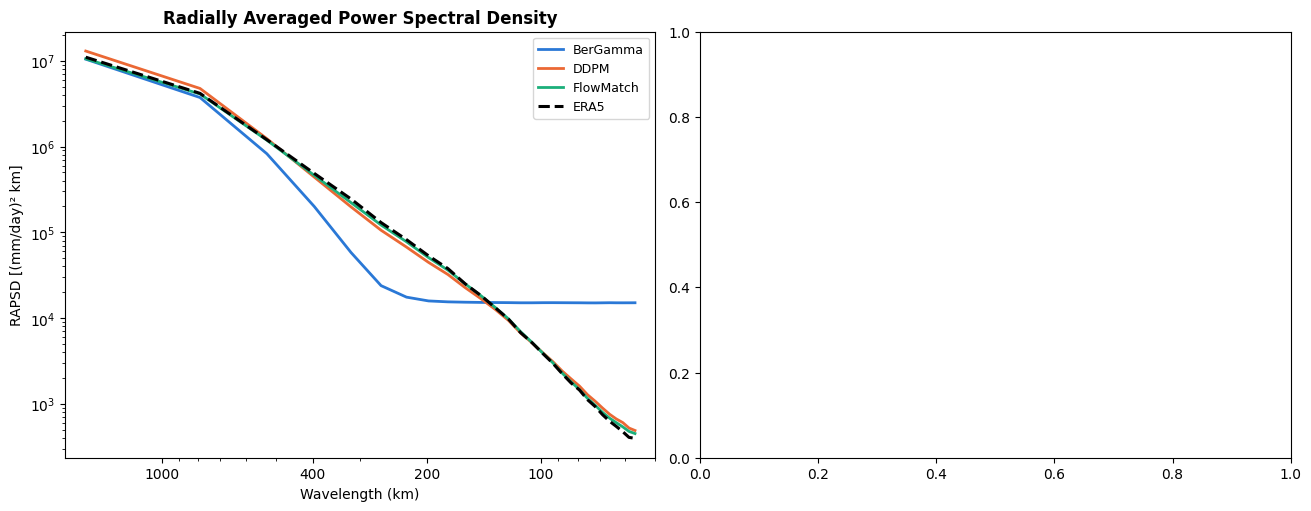

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
plot_rapsd(rapsd_ref, rapsd_mod, ref_name="ERA5", units="mm/day", ax=axes[0])
# plot_rapsd_ratio(ratios, ref_name="ERA5", ax=axes[1])
fig.savefig(ROOT / "figures" / "rapsd_test_period.png", bbox_inches="tight", dpi=300)
plt.show()